# What does diffusion conversion buy? An interactive tour

This notebook walks through the main results of our CS787 project. It runs on a laptop in seconds: it reads the
summary of our evaluations (`results/summary.json`) and recorded generations (`results/demo_data.json`). No GPU needed.

**The question.** BYOD (Kuiper & Bagheri, 2026) turns an autoregressive (AR) chat model into a masked-diffusion model
by training one LoRA adapter for about three GPU-hours. It compares the result only with the untouched original
model, so you cannot tell what diffusion costs from what BYOD's fine-tuning data costs. We trained an **AR control**:
same base model, same data in the same order, same LoRA, same number of updates. Only the diffusion part differs.

**Arms** (one column per model in the tables below):
- `parent`: the original model, untouched.
- `ar-control`: parent + our same-data AR LoRA (causal attention, next-token loss).
- `byod-released`: BYOD's published conversion. `byod-retrained`: our own rerun of BYOD's recipe.
- `llada`: LLaDA 8B, a diffusion model pretrained from scratch, as a reference.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RES = Path("../results") if Path("../results").exists() else Path("results")
summary = json.loads((RES / "summary.json").read_text())
cells = summary["cells"]          # "<arm>/<task>" -> accuracy, timing, sample size, 95% interval
demo = json.loads((RES / "demo_data.json").read_text())
print(len(cells), "measured (arm, task) cells")

118 measured (arm, task) cells


## 1. Accuracy on the benchmarks

Up to 500 examples per task. `he_single` / `he_multi` are HumanEval infilling (fill one missing line, or several),
scored strictly. Infilling arms are told the true gap length.

Note: every arm here gets a 256-token answer budget. The original Qwen writes long worked solutions, so on GSM8K it
scores 0.648 at 256 tokens and 0.922 at 512 (report §3.2); the AR control, which learned short answers, stays at 0.50.

In [2]:
TASKS = ["gsm8k", "mmlu", "arc_c", "humaneval", "mbpp", "he_single_strict", "he_multi_strict"]

def table(prefix, arms):
    rows = {arm: {t: cells.get(f"{prefix}-{arm}/{t}" if arm != "llada" else f"llada/{t}", {}).get("acc") for t in TASKS}
            for arm in arms}
    return pd.DataFrame(rows).T.round(3)

print("Qwen2.5 7B")
display(table("qwen", ["parent", "ar-control", "byod-retrained", "byod-released", "llada"]))
print("Ministral 8B")
display(table("ministral", ["parent", "ar-control", "byod-released"]))

Qwen2.5 7B


,gsm8k,mmlu,arc_c,humaneval,mbpp,he_single_strict,he_multi_strict
parent,0.648,0.720,0.914,0.695,0.739,0.688,0.436
ar-control,0.502,0.738,0.914,0.726,0.739,0.524,0.350
byod-retrained,0.434,0.672,0.844,0.274,0.393,0.664,0.224
byod-released,0.618,0.672,0.862,0.268,0.416,0.720,0.252
llada,0.588,0.604,0.878,0.341,0.486,0.886,0.510


Ministral 8B


,gsm8k,mmlu,arc_c,humaneval,mbpp,he_single_strict,he_multi_strict
parent,0.710,0.566,0.716,0.659,0.677,0.634,0.388
ar-control,0.838,0.646,0.830,0.665,0.708,0.696,0.400
byod-released,0.646,0.634,0.840,0.280,0.412,0.726,0.282


## 2. What diffusion itself costs (data held fixed)

The fair comparison is the AR control against the conversion: same data, same budget. Bars show how many points the
AR control is ahead. Positive means diffusion costs accuracy.

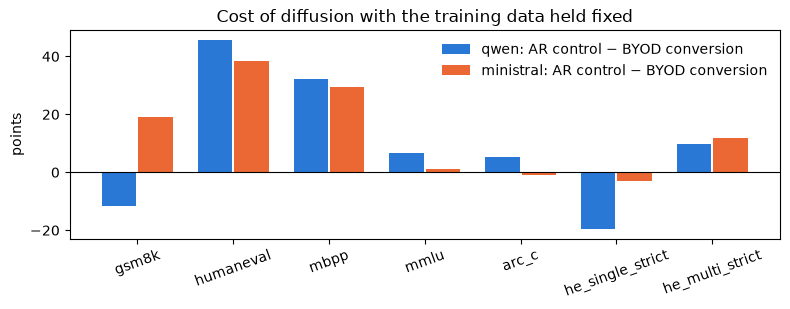

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
tasks = ["gsm8k", "humaneval", "mbpp", "mmlu", "arc_c", "he_single_strict", "he_multi_strict"]
for i, (prefix, conv, colour) in enumerate([("qwen", "byod-released", "#2A78D6"), ("ministral", "byod-released", "#EB6834")]):
    gaps = [100 * (cells[f"{prefix}-ar-control/{t}"]["acc"] - cells[f"{prefix}-{conv}/{t}"]["acc"]) for t in tasks]
    ax.bar([x + 0.38 * i for x in range(len(tasks))], gaps, width=0.36, label=f"{prefix}: AR control − BYOD conversion", color=colour)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks([x + 0.19 for x in range(len(tasks))], tasks, rotation=20)
ax.set_ylabel("points"); ax.legend(frameon=False); ax.set_title("Cost of diffusion with the training data held fixed")
plt.tight_layout(); plt.show()

## 3. The compute dial

A diffusion model fills a fixed number of positions (here 256) in a number of **steps** that you choose before
generating. Fewer steps means more tokens committed per step, so less compute. A non-thinking AR model has no such
switch: it pays one forward pass per token it writes.

The dial is real (time falls linearly with steps), but look where the points land relative to the AR models.

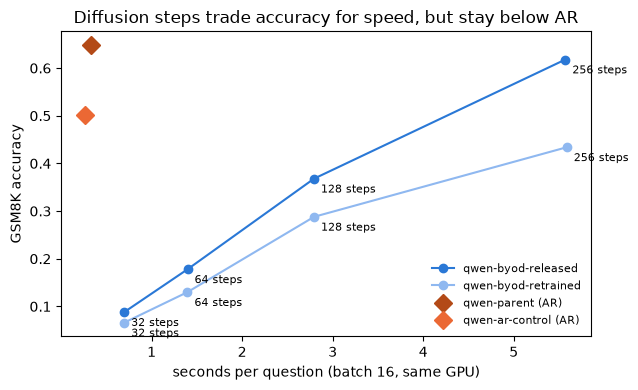

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for arm, colour in [("qwen-byod-released", "#2A78D6"), ("qwen-byod-retrained", "#8FB8F0")]:
    pts = []
    for steps, key in [(32, "gsm8k_s32"), (64, "gsm8k_s64"), (128, "gsm8k_s128"), (256, "gsm8k")]:
        c = cells[f"{arm}/{key}"]; pts.append((c["s_per_example"], c["acc"], steps))
    ax.plot([p[0] for p in pts], [p[1] for p in pts], "o-", color=colour, label=arm)
    for s, a, n in pts: ax.annotate(f"{n} steps", (s, a), textcoords="offset points", xytext=(5, -10), fontsize=8)
for arm, colour in [("qwen-parent", "#B34A17"), ("qwen-ar-control", "#EB6834")]:
    c = cells[f"{arm}/gsm8k"]; ax.plot(c["s_per_example"], c["acc"], "D", ms=9, color=colour, label=f"{arm} (AR)")
ax.set_xlabel("seconds per question (batch 16, same GPU)"); ax.set_ylabel("GSM8K accuracy")
ax.set_title("Diffusion steps trade accuracy for speed, but stay below AR"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Infilling needs the exact gap length

Every diffusion infilling run is told how many tokens the missing line has. Here we give it the wrong length
(0.5×, 1.5×, 2×). The AR control (dashed) needs no length at all.

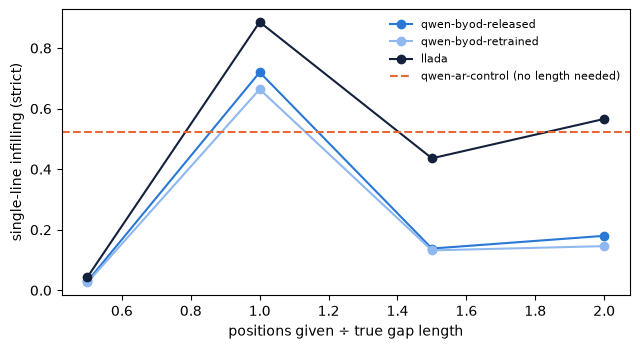

In [5]:
mult = [0.5, 1.0, 1.5, 2.0]
key = lambda m: "he_single_strict" if m == 1.0 else f"he_single_strict_gapx{m:g}"
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for arm, colour in [("qwen-byod-released", "#2A78D6"), ("qwen-byod-retrained", "#8FB8F0"), ("llada", "#14213D")]:
    ax.plot(mult, [cells[f"{arm}/{key(m)}"]["acc"] for m in mult], "o-", color=colour, label=arm)
ax.axhline(cells["qwen-ar-control/he_single_strict"]["acc"], ls="--", color="#EB6834", label="qwen-ar-control (no length needed)")
ax.set_xlabel("positions given ÷ true gap length"); ax.set_ylabel("single-line infilling (strict)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

## 5. Watch a diffusion model write

These are recorded generations. Each token carries the step at which it was unmasked. Move the slider (or read the
printed frames) to see the answer appear out of order. `░` is a still-masked position.

In [6]:
def frame(run, step, width=24):
    toks = run["tokens"]
    out = "".join(t["t"] if t["s"] <= step else "░" for t in toks if not t["end"] or t["s"] <= step)
    return out

ex = demo["gsm8k"]
print("Question:", ex["question"], "| correct answer:", ex["answer"])
run = ex["runs"]["released_256"]
last = max(t["s"] for t in run["tokens"])
for step in [0, 5, 10, 20, last]:
    print(f"--- after step {step} ---"); print(frame(run, step)[:200])

Question: Ali had $21. Leila gave him half of her $100. How much does Ali have now? | correct answer: 71
--- after step 0 ---
Le░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░
--- after step 5 ---
Leila gave Ali $░0░░░░░░░░░░░░░░░░░░░░░░░░░░░░
--- after step 10 ---
Leila gave Ali $100 / 2░░░░░░░░░░░░░░░░░░░░░░░░
--- after step 20 ---
Leila gave Ali $100 / 2 = $50.
Ali now has $░░ +░░░░░░░░░░░░
--- after step 255 ---
Leila gave Ali $100 / 2 = $50.
Ali now has $21 + $50 = $71.
#### 71


In [7]:
# Interactive version (needs ipywidgets; in Colab it works out of the box)
try:
    import ipywidgets as w
    choice = w.Dropdown(options=list(ex["runs"]), description="run")
    step = w.IntSlider(min=0, max=255, value=10, description="step")
    def show(run_name, s):
        r = ex["runs"][run_name]
        print(r["label"]); print(frame(r, s))
    w.interact(show, run_name=choice, s=step)
except ImportError:
    print("ipywidgets not installed; the printed frames above show the same thing.")

interactive(children=(Dropdown(description='run', options=('released_256', 'released_32', 'llada_256'), value=…

Compare `released_256` (one token per step) with `released_32` (eight tokens per step): with fewer steps,
neighbouring tokens are chosen without seeing each other, which is where repeated or broken words come from.

## Try the models yourself

Our adapters are public: see `WEIGHTS_README.md` in the repository root for the Drive link and loading code. The AR
controls are ordinary PEFT adapters on the base model. The diffusion conversion needs BYOD's code to sample
(`eval/arms.py` and `eval/sampling.py` show how), and a GPU with about 24 GB of memory.